# Can we search English medical docs with Khmer/Lao/Vietnamese queries?

## The question
A doctor in Cambodia types a question in Khmer. Our medical knowledge base is in English. 
Can the embedding model understand that these two are about the same thing — **without translating first?**

## What we test
- **10 real medical questions**, each written in 4 languages (EN, KH, LO, VI)
- **10 correct answer chunks** from our guideline (in English)
- **2 embedding models**: multilingual-e5-small and BGE-M3

For each question, we check: does the model put the query close to the correct chunk?

## What we decide
- If Khmer query lands near the right English chunk → **no translation needed**
- If it lands far away → **we must translate first with NLLB-200**


In [1]:
# Step 0: Install what we need (run once)
# !pip install sentence-transformers torch
# Note: senv needs sentence-transformers; it was installed with transformers==4.50.0 / torch==2.8.0 pinned


In [2]:
# Step 1: Load two embedding models
# These models turn text into numbers (vectors).
# Similar texts → similar vectors → high cosine similarity (close to 1.0)
# Different texts → different vectors → low cosine similarity (close to 0.0)

import os
# transformers is picked up from ~/.local, which also sees TensorFlow + Keras 3 and fails to import.
# We only use PyTorch, so turn TF off before importing.
os.environ["USE_TF"] = "0"

from sentence_transformers import SentenceTransformer

print("Loading model 1: multilingual-e5-small (130 MB)...")
e5_model = SentenceTransformer("intfloat/multilingual-e5-small")

print("Loading model 2: BGE-M3 (2 GB)...")
bge_model = SentenceTransformer("BAAI/bge-m3")

print("Both models ready.")


/mnt/mahdipou/miniconda3/envs/senv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading model 1: multilingual-e5-small (130 MB)...


Loading model 2: BGE-M3 (2 GB)...


Both models ready.


In [3]:
# Step 2: Our test data
# 10 medical questions, each in 4 languages
# + the correct English chunk each question should find

questions = [
    {
        "topic": "Sepsis antibiotics",
        "en": "What antibiotics should be used for sepsis?",
        "km": "តើអង់ទីប៊ីយោទិចអ្វីខ្លះដែលគួរប្រើសម្រាប់ sepsis?",
        "lo": "ຄວນໃຊ້ຢາຕ້ານເຊື້ອຈຸລະຊີບອັນໃດສຳລັບ sepsis?",
        "vi": "Nên dùng kháng sinh nào cho sepsis?",
        "correct_chunk": "Sepsis and septic shock management. Empirical antibiotherapy selection based on suspected source. Broad spectrum antibiotics within one hour."
    },
    {
        "topic": "Hemorrhagic shock",
        "en": "How to manage hemorrhagic shock?",
        "km": "តើគ្រប់គ្រង hemorrhagic shock យ៉ាងដូចម្តេច?",
        "lo": "ຈັດການ hemorrhagic shock ແນວໃດ?",
        "vi": "Xử trí sốc mất máu như thế nào?",
        "correct_chunk": "Hemorrhagic shock management. Initial fluid resuscitation with crystalloids. Massive transfusion protocol activation. Control bleeding source."
    },
    {
        "topic": "NEWS-2 scoring",
        "en": "What are the NEWS-2 scoring parameters?",
        "km": "តើប៉ារ៉ាម៉ែត្រនៃការដាក់ពិន្ទុ NEWS-2 មានអ្វីខ្លះ?",
        "lo": "ຕົວກຳນົດການໃຫ້ຄະແນນ NEWS-2 ມີຫຍັງແດ່?",
        "vi": "Các thông số chấm điểm NEWS-2 là gì?",
        "correct_chunk": "National Early Warning Score NEWS-2. Parameters: respiratory rate, oxygen saturation SpO2, systolic blood pressure, pulse rate, consciousness, temperature."
    },
    {
        "topic": "Snake bite",
        "en": "How to treat snake bite?",
        "km": "តើព្យាបាលការខាំពស់យ៉ាងដូចម្តេច?",
        "lo": "ປິ່ນປົວງູກັດແນວໃດ?",
        "vi": "Điều trị rắn cắn như thế nào?",
        "correct_chunk": "Snake bite management. Identification of venomous species. Antivenom administration. Thai Red Cross antivenom dosing. Wound care and monitoring."
    },
    {
        "topic": "Anaphylaxis adrenaline",
        "en": "What is the dose of adrenaline in anaphylaxis?",
        "km": "តើកម្រិតថ្នាំ adrenaline ក្នុង anaphylaxis ប៉ុន្មាន?",
        "lo": "ປະລິມານຢາ adrenaline ໃນ anaphylaxis ແມ່ນຫຍັງ?",
        "vi": "Liều adrenaline trong phản vệ là bao nhiêu?",
        "correct_chunk": "Allergic reaction and anaphylaxis. Intramuscular epinephrine adrenaline 0.5mg adults. Second dose after 5 minutes if no improvement."
    },
    {
        "topic": "Paracetamol overdose",
        "en": "How to manage paracetamol overdose?",
        "km": "តើគ្រប់គ្រងការលើសកម្រិត paracetamol យ៉ាងដូចម្តេច?",
        "lo": "ຈັດການກິນ paracetamol ເກີນຂະໜາດແນວໃດ?",
        "vi": "Xử trí quá liều paracetamol như thế nào?",
        "correct_chunk": "Paracetamol acetaminophen poisoning. N-acetylcysteine NAC protocol. Rumack-Matthew nomogram. Treatment within 8 hours of ingestion."
    },
    {
        "topic": "Hyperkalemia",
        "en": "Emergency treatment of hyperkalemia",
        "km": "ការព្យាបាលបន្ទាន់នៃ hyperkalemia ដោយប្រើ calcium",
        "lo": "ການປິ່ນປົວສຸກເສີນ hyperkalemia ດ້ວຍ calcium",
        "vi": "Điều trị cấp cứu tăng kali máu bằng calcium",
        "correct_chunk": "Hyperkalemia emergency treatment. Calcium gluconate for cardiac membrane stabilization. Insulin and glucose for potassium shifting."
    },
    {
        "topic": "STEMI treatment",
        "en": "STEMI reperfusion therapy and timing",
        "km": "ការព្យាបាល reperfusion និងពេលវេលាសម្រាប់ STEMI",
        "lo": "ການປິ່ນປົວ reperfusion ແລະໄລຍະເວລາສຳລັບ STEMI",
        "vi": "Điều trị tái tưới máu STEMI và thời gian",
        "correct_chunk": "ST elevation myocardial infarction STEMI. Primary PCI within 90 minutes. Thrombolysis within 30 minutes. Dual antiplatelet therapy."
    },
    {
        "topic": "Heart failure",
        "en": "Heart failure treatment with ACE inhibitor",
        "km": "ការព្យាបាល heart failure ដោយប្រើ ACE inhibitor",
        "lo": "ການປິ່ນປົວ heart failure ດ້ວຍ ACE inhibitor",
        "vi": "Điều trị suy tim bằng thuốc ức chế ACE",
        "correct_chunk": "Chronic heart failure management. ACE inhibitors first line. Beta blockers. Mineralocorticoid receptor antagonists. SGLT2 inhibitors."
    },
    {
        "topic": "Hyponatremia",
        "en": "Correction of severe hyponatremia",
        "km": "ការកែតម្រូវ hyponatremia ធ្ងន់ធ្ងរដោយប្រើ sodium",
        "lo": "ການແກ້ໄຂ hyponatremia ຮ້າຍແຮງດ້ວຍ sodium",
        "vi": "Điều chỉnh hạ natri máu nặng bằng sodium",
        "correct_chunk": "Hyponatremia correction. Hypertonic saline 3 percent for severe cases. Maximum correction 8 mEq per liter per 24 hours."
    },
]

# Also create some WRONG chunks (distractors) to make the test harder
# The model must pick the right one from all 10, not just say "yes/no"
wrong_chunks = [
    "Diabetes mellitus type 2 management. Metformin as first line. HbA1c target below 7 percent.",
    "Pneumonia community acquired. Amoxicillin for mild cases. Chest X-ray for diagnosis.",
    "Asthma acute exacerbation. Salbutamol nebulizer. Oral prednisolone. Peak flow monitoring.",
]

all_chunks = [q["correct_chunk"] for q in questions] + wrong_chunks

print(f"Test ready: {len(questions)} questions x 4 languages")
print(f"Searching among {len(all_chunks)} chunks ({len(questions)} correct + {len(wrong_chunks)} distractors)")


Test ready: 10 questions x 4 languages
Searching among 13 chunks (10 correct + 3 distractors)


In [4]:
# Step 3: Run the test
# For each question in each language:
#   1. Turn the question into a vector
#   2. Turn all 13 chunks into vectors
#   3. Find which chunk is closest (highest cosine similarity)
#   4. Check: is it the CORRECT chunk?

import numpy as np

def test_model(model, model_name, query_prefix="", chunk_prefix=""):
    """Test one embedding model across all languages."""
    
    # Embed all chunks once (they're all English)
    chunk_vectors = model.encode(
        [f"{chunk_prefix}{c}" for c in all_chunks], 
        normalize_embeddings=True
    )
    
    results = []
    
    for q in questions:
        # The correct chunk is at this position in all_chunks
        correct_position = questions.index(q)
        
        for lang in ["en", "km", "lo", "vi"]:
            # Embed the query
            query_text = f"{query_prefix}{q[lang]}"
            query_vector = model.encode([query_text], normalize_embeddings=True)
            
            # Cosine similarity = dot product (vectors are already normalized)
            similarities = (query_vector @ chunk_vectors.T)[0]
            
            # Which chunk was most similar?
            best_chunk_position = int(np.argmax(similarities))
            correct_similarity = float(similarities[correct_position])
            best_similarity = float(similarities[best_chunk_position])
            
            # Did the model pick the right chunk?
            found_correct = (best_chunk_position == correct_position)
            
            results.append({
                "topic": q["topic"],
                "language": lang,
                "model": model_name,
                "similarity_to_correct": round(correct_similarity, 3),
                "found_correct_chunk": found_correct,
                "best_match": all_chunks[best_chunk_position][:50] + "...",
            })
    
    return results

# Run both models
print("Testing multilingual-e5-small...")
# e5 models need special prefixes to work well
results_e5 = test_model(e5_model, "e5-small", 
                         query_prefix="query: ", 
                         chunk_prefix="passage: ")

print("Testing BGE-M3...")
results_bge = test_model(bge_model, "BGE-M3")

all_results = results_e5 + results_bge
print(f"Done! {len(all_results)} tests completed.")


Testing multilingual-e5-small...


Testing BGE-M3...


Done! 80 tests completed.


In [5]:
# Step 4: See the results
# 
# What we care about:
#   - "similarity_to_correct": how close was the query to the RIGHT chunk? (0 to 1)
#   - "found_correct_chunk": did the model pick the RIGHT chunk as #1? (True/False)
#
# If English gets 0.85 and Khmer gets 0.80 → great, Khmer works
# If English gets 0.85 and Khmer gets 0.30 → bad, need translation

lang_names = {"en": "English", "km": "Khmer", "lo": "Lao", "vi": "Vietnamese"}

for model_name in ["e5-small", "BGE-M3"]:
    model_results = [r for r in all_results if r["model"] == model_name]
    
    print(f"\n{'='*60}")
    print(f"  {model_name}")
    print(f"{'='*60}")
    print(f"{'Language':<14} {'Avg Similarity':>16} {'Found Correct':>15} {'Verdict':>20}")
    print(f"{'-'*65}")
    
    # Get English baseline
    en_results = [r for r in model_results if r["language"] == "en"]
    en_avg_sim = np.mean([r["similarity_to_correct"] for r in en_results])
    
    for lang in ["en", "km", "lo", "vi"]:
        lang_results = [r for r in model_results if r["language"] == lang]
        avg_sim = np.mean([r["similarity_to_correct"] for r in lang_results])
        accuracy = np.mean([r["found_correct_chunk"] for r in lang_results])
        
        # How much worse than English?
        drop = (en_avg_sim - avg_sim) / en_avg_sim * 100
        
        if accuracy >= 0.8 and drop < 10:
            verdict = "DIRECT OK"
        elif accuracy >= 0.5 and drop < 20:
            verdict = "MAYBE OK"
        else:
            verdict = "NEED TRANSLATE"
        
        print(f"{lang_names[lang]:<14} {avg_sim:>16.3f} {accuracy:>14.0%} {verdict:>20}")



  e5-small
Language         Avg Similarity   Found Correct              Verdict
-----------------------------------------------------------------
English                   0.897           100%            DIRECT OK
Khmer                     0.856            90%            DIRECT OK
Lao                       0.845            80%            DIRECT OK
Vietnamese                0.828           100%            DIRECT OK

  BGE-M3
Language         Avg Similarity   Found Correct              Verdict
-----------------------------------------------------------------
English                   0.678           100%            DIRECT OK
Khmer                     0.638           100%            DIRECT OK
Lao                       0.638           100%            DIRECT OK
Vietnamese                0.630           100%            DIRECT OK


In [6]:
# Step 5: Which questions fail in which language?
# This shows exactly WHERE cross-lingual search breaks down

print("\nPer-question results for BGE-M3:")
print(f"{'Topic':<22} {'EN':>5} {'KH':>5} {'LO':>5} {'VI':>5}  {'KH ok?':>7} {'LO ok?':>7} {'VI ok?':>7}")
print("-" * 80)

bge_results = [r for r in all_results if r["model"] == "BGE-M3"]

for q in questions:
    row = {"en": None, "km": None, "lo": None, "vi": None}
    found = {"en": None, "km": None, "lo": None, "vi": None}
    
    for r in bge_results:
        if r["topic"] == q["topic"]:
            row[r["language"]] = r["similarity_to_correct"]
            found[r["language"]] = r["found_correct_chunk"]
    
    km_ok = "yes" if found["km"] else "NO"
    lo_ok = "yes" if found["lo"] else "NO"
    vi_ok = "yes" if found["vi"] else "NO"
    
    print(f"{q['topic']:<22} {row['en']:>5.2f} {row['km']:>5.2f} {row['lo']:>5.2f} {row['vi']:>5.2f}  {km_ok:>7} {lo_ok:>7} {vi_ok:>7}")



Per-question results for BGE-M3:
Topic                     EN    KH    LO    VI   KH ok?  LO ok?  VI ok?
--------------------------------------------------------------------------------
Sepsis antibiotics      0.64  0.58  0.60  0.62      yes     yes     yes
Hemorrhagic shock       0.72  0.69  0.70  0.63      yes     yes     yes
NEWS-2 scoring          0.60  0.58  0.57  0.56      yes     yes     yes
Snake bite              0.65  0.52  0.51  0.58      yes     yes     yes
Anaphylaxis adrenaline  0.71  0.70  0.68  0.65      yes     yes     yes
Paracetamol overdose    0.59  0.53  0.56  0.62      yes     yes     yes
Hyperkalemia            0.76  0.74  0.73  0.68      yes     yes     yes
STEMI treatment         0.66  0.63  0.64  0.64      yes     yes     yes
Heart failure           0.71  0.72  0.71  0.67      yes     yes     yes
Hyponatremia            0.73  0.69  0.69  0.65      yes     yes     yes


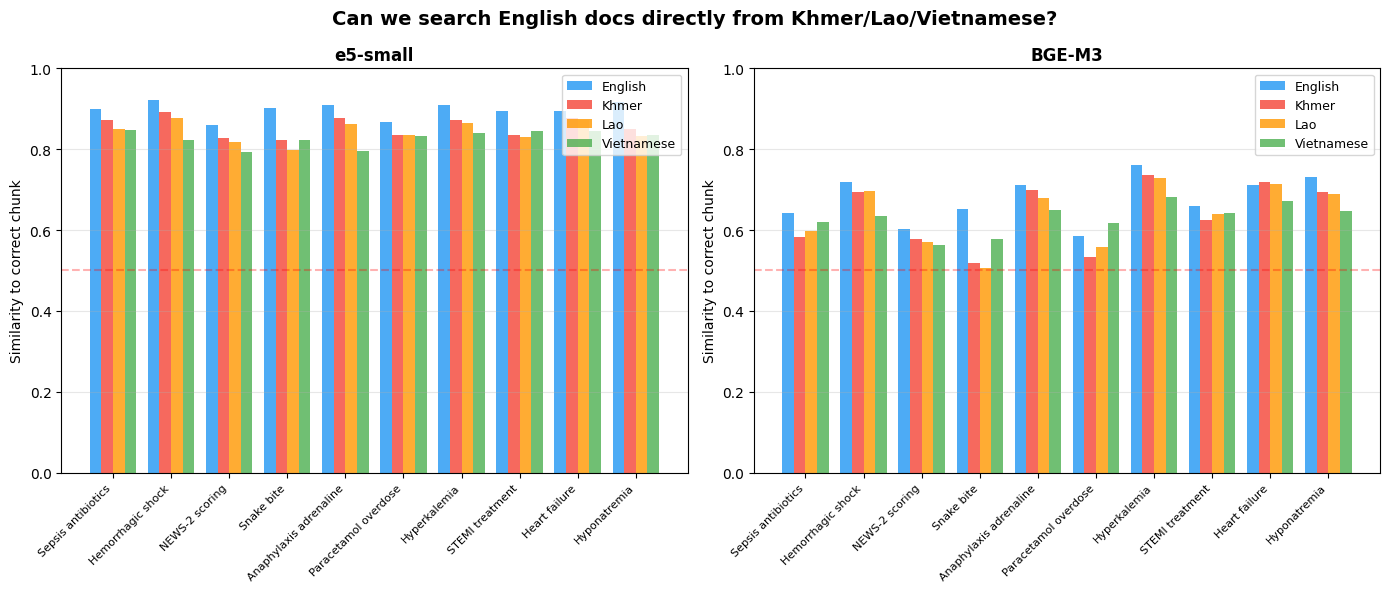

Saved: out/crosslingual_results.png


In [7]:
# Step 6: Visual summary

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Can we search English docs directly from Khmer/Lao/Vietnamese?",
             fontsize=14, fontweight="bold")

colors = {"English": "#2196F3", "Khmer": "#F44336", "Lao": "#FF9800", "Vietnamese": "#4CAF50"}

for ax_idx, model_name in enumerate(["e5-small", "BGE-M3"]):
    ax = axes[ax_idx]
    model_results = [r for r in all_results if r["model"] == model_name]
    
    topics = [q["topic"] for q in questions]
    x = np.arange(len(topics))
    w = 0.2
    
    for i, (lang, lang_name) in enumerate([("en","English"), ("km","Khmer"), ("lo","Lao"), ("vi","Vietnamese")]):
        sims = []
        for q in questions:
            r = [r for r in model_results if r["topic"] == q["topic"] and r["language"] == lang][0]
            sims.append(r["similarity_to_correct"])
        ax.bar(x + i*w - 1.5*w, sims, w, label=lang_name, color=colors[lang_name], alpha=0.8)
    
    ax.set_xticks(x)
    ax.set_xticklabels(topics, rotation=45, ha="right", fontsize=8)
    ax.set_ylabel("Similarity to correct chunk")
    ax.set_title(model_name, fontweight="bold")
    ax.legend(fontsize=9)
    ax.set_ylim(0, 1)
    ax.axhline(y=0.5, color="red", linestyle="--", alpha=0.3, label="threshold")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
os.makedirs("out", exist_ok=True)
plt.savefig("out/crosslingual_results.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved: out/crosslingual_results.png")


In [8]:
# Step 7: Final decision
# 
# Fill this in after looking at the results above:

print("""
DECISION
========

Based on the test results:

  Vietnamese:  _____ (DIRECT OK / NEED TRANSLATE)
  Lao:         _____ (DIRECT OK / NEED TRANSLATE) 
  Khmer:       _____ (DIRECT OK / NEED TRANSLATE)
  
  Best model:  _____ (e5-small / BGE-M3)

If DIRECT OK   → user query goes straight to embedding → search
If NEED TRANSLATE → user query → NLLB-200 → English → embedding → search

This decides whether NLLB-200 is in the pipeline or not.
""")



DECISION

Based on the test results:

  Vietnamese:  _____ (DIRECT OK / NEED TRANSLATE)
  Lao:         _____ (DIRECT OK / NEED TRANSLATE) 
  Khmer:       _____ (DIRECT OK / NEED TRANSLATE)
  
  Best model:  _____ (e5-small / BGE-M3)

If DIRECT OK   → user query goes straight to embedding → search
If NEED TRANSLATE → user query → NLLB-200 → English → embedding → search

This decides whether NLLB-200 is in the pipeline or not.

